In [28]:
n=19
g=1.2
mu=2.5
T=50
import numpy as np
import scipy
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt
from scipy.optimize import root

In [29]:
def part1q1a(n, g, mu, T):
    """Part 1, question 1 (a)
    Use the variable inputs if/as needed.
    Input:
    n: number of ODEs
    g,mu: model parameters
    T: time at which perturbation energy ratio should be maximized

    Output:
    xbar: n-element array containing non-trivial equilibrium solution
    xtilde0: n-element array corresponding to computed initial condition
    eratio: computed maximum perturbation energy ratio
    """
    xbar = np.zeros(n)
    xtilde0 = np.zeros(n)
    eratio = 0.0

    def model(X, n, g, mu):
        dXdt = np.zeros(n)
        dXdt[0] = X[0] * (1 - g * X[-2] - X[0] - g * X[1] + mu * X[-3])
        dXdt[1] = X[1] * (1 - g * X[-1] - X[1] - g * X[2])
        dXdt[2 : n - 1] = X[2 : n - 1] * (
            1 - g * X[0 : n - 3] - X[2 : n - 1] - g * X[3:n]
        )
        dXdt[-1] = X[-1] * (1 - g * X[-3] - X[-1] - g * X[0])
        return dXdt

    eventus = root(
        model,
        1 / (2 * g + 1) + 0.1 * np.random.rand(n),
        method="krylov",
        args=(n, g, mu),
    )
    x_bar = eventus.x

    B = np.zeros([n, n])
    for i in range(2, n - 1):
        B[i, i] = -1
        B[i, i - 2] = -g
        B[i, i + 1] = -g

    B[0, 0] = -1
    B[0, n - 2] = -g
    B[0, 1] = -g
    B[0, n - 3] = mu

    B[1, 1] = -1
    B[1, n - 1] = -g
    B[1, 2] = -g

    B[n - 1, n - 1] = -1
    B[n - 1, n - 3] = -g
    B[n - 1, 0] = -g

    M = np.zeros([n, n])

    for i in range(n):
        M[i, i] = 1 + np.matmul(B[i, :], x_bar)

    for i in range(n):
        for j in range(n):
            M[i, j] += B[i, j] * x_bar[i]

    matM = scipy.linalg.expm(M * T)

    U, Sigma, VT = np.linalg.svd(matM)

    eratio = Sigma[0] ** 2

    xtilde0 = VT[0, :]

    xbar = x_bar

    return xbar, xtilde0, eratio

In [30]:
def simulate1(n, X0=-1, Nt=2000, tf=1000, g=1.0, mu=0.0, flag_display=False):
    """
    Simulation code for part 1
    Input:
        n: number of ODEs
        X0: initial condition if n-element numpy array. If X0 is an integer, the code will set
        the initial condition (otherwise an array is expected).
        Nt: number of time steps
        tf: final time
        g,mu: model parameters
        flag_display: will generate a contour plot displaying results if True
    Output:
    t,x: numpy arrays containing times and simulation results
    """

    def model(t, X, n, g, mu):
        """
        Defines the system of ODEs

        Input:
        - t: time
        - X: array of variables [x_0, x_1, ..., x_{n-1}]
        - g, mu: scalar model parameters
        - n: number of ODEs (size of the system)

        Returns:
        - dXdt: array of derivatives [dx_0/dt, dx_1/dt, ..., dx_{n-1}/dt]
        """
        dXdt = np.zeros(n)
        dXdt[0] = X[0] * (1 - g * X[-2] - X[0] - g * X[1] + mu * X[-3])
        dXdt[1] = X[1] * (1 - g * X[-1] - X[1] - g * X[2])
        dXdt[2 : n - 1] = X[2 : n - 1] * (
            1 - g * X[0 : n - 3] - X[2 : n - 1] - g * X[3:n]
        )
        dXdt[-1] = X[-1] * (1 - g * X[-3] - X[-1] - g * X[0])
        return dXdt

    # Parameters
    t_span = (0, tf)  # Time span for the integration
    if type(X0) == int:  # (modified from original version)
        X0 = 1 / (2 * g + 1) + 0.001 * np.random.rand(
            n
        )  # Random initial conditions, modify if needed

    # Solve the system
    solution = solve_ivp(
        fun=model,
        t_span=t_span,
        y0=X0,
        args=(n, g, mu),
        method="BDF",
        rtol=1e-10,
        atol=1e-10,
        t_eval=np.linspace(t_span[0], t_span[1], Nt),  # Times to evaluate the solution
    )

    t, x = (
        solution.t,
        solution.y,
    )  # (in original version of code this line was inside if-block below)
    if flag_display:
        # Plot the solution
        plt.contour(t, np.arange(n), x, 20)
        plt.xlabel("t")  # (corrected axis labels)
        plt.ylabel("i")
    return t, x

Linear analysis predicted energy ratio: 26879.8827
Simulation computed energy ratio: 26850.9524


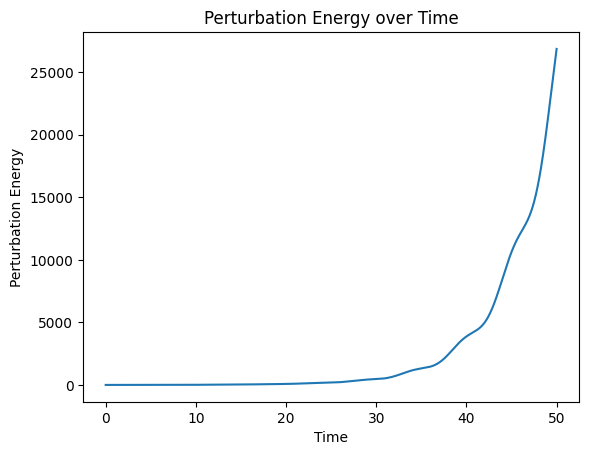

In [31]:
# Set parameters for the test
n = 19  
g = 1.2 
mu = 2.5  
T = 50  

# Results from 1q1a
xbar, xtilde0, eratio_linear= part1q1a(n, g, mu, T)

# Results from simulate1
t, x = simulate1(n=n, X0=xbar+(1e-5)*xtilde0.real, tf=T, g=g, mu=mu, flag_display=False)

perturbatio = x - xbar[:, None]  
e_t0 = np.sum(perturbatio[:, 0] ** 2)  
e_tT = np.sum(perturbatio[:, -1] ** 2)  
eratio_simulation = e_tT / e_t0  

# Compare results
print(f"Linear analysis predicted energy ratio: {eratio_linear:.4f}")
print(f"Simulation computed energy ratio: {eratio_simulation:.4f}")

# Optional: Plot perturbation energy over time
e_over_time = np.sum(perturbatio**2, axis=0)/e_t0 # Energy at each time step
plt.plot(t, e_over_time)
plt.xlabel("Time")
plt.ylabel("Perturbation Energy")
plt.title("Perturbation Energy over Time")
plt.show()

In [35]:
def part1q2():
    """Part 1, question 2:
    Add input/output if/as needed.
    """

    # add code here
    from scipy.signal import welch

    def analyze_case(n, g, mu, Nt, tf):
        """
        Analyzes a single case and produces plots and statistics.
        """
        X0 = -1
        # t, X = simulate1(n=n, X0=X0, tf=T, g=g, mu=mu, flag_display=True)
        t, X = simulate1(n=n, X0=X0, tf=T, g=g, mu=mu, flag_display=False)
        # Discard the transient (e.g., first 10% of time)
        transient_cutoff = int(0.4 * len(t))
        t = t[transient_cutoff:]
        X = X[:, transient_cutoff:]

        # Split the figures for better visualization
        num_figures = (n + 19) // 20  # Divide trajectories into groups of 20
        for fig_idx in range(num_figures):
            plt.figure(figsize=(12, 6))
            start_idx = fig_idx * 20
            end_idx = min(start_idx + 20, n)
            for i in range(start_idx, end_idx):
                plt.plot(t, X[i], label=f"x_{i}")
            plt.xlabel("Time")
            plt.ylabel("x values")
            plt.title(f"Time Evolution for n={n}, g={g}, mu={mu}, Group {fig_idx + 1}")
            plt.grid(True)
            # plt.legend()
            plt.show()

        # Compute and Plot PSD for all trajectories on one figure
        fs = 1 / (t[1] - t[0])  # Sampling frequency
        plt.figure(figsize=(8, 6))  # Single figure for all PSDs

        for i in range(n):
            freqs, psd = welch(X[i], fs=fs, nperseg=256)  # Welch method
            plt.semilogy(freqs, psd, label=f"x_{i}")

        # Add labels, legend, and grid to the single plot
        plt.xlabel("Frequency (Hz)")
        plt.ylabel("Power Spectral Density")
        plt.title(f"Power Spectral Density for all trajectories (n={n})")
        plt.grid(True)
        # plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize='small')  # Legend outside the plot
        plt.tight_layout()  # Adjust layout to accommodate the legend
        plt.show()

        return t, X

    g = 1  # gamma
    mu = 0  # mu

    # Case A: n = 9
    print("Analyzing Case A: n = 9")
    t_A, X_A = analyze_case(n=9, g=g, mu=mu, Nt=1000, tf=500)

    # Case B: n = 20
    print("Analyzing Case B: n = 20")
    t_B, X_B = analyze_case(n=20, g=g, mu=mu, Nt=2000, tf=800)

    # Case C: n = 59
    print("Analyzing Case C: n = 59")
    t_C, X_C = analyze_case(n=59, g=g, mu=mu, Nt=3000, tf=1000)

    # Return results for further analysis
    return (t_A, X_A), (t_B, X_B), (t_C, X_C)

In [36]:
n = 9
g = 1
mu = 0
T = 200
import numpy as np
import scipy
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt
from scipy.optimize import root

Analyzing Case A: n = 9


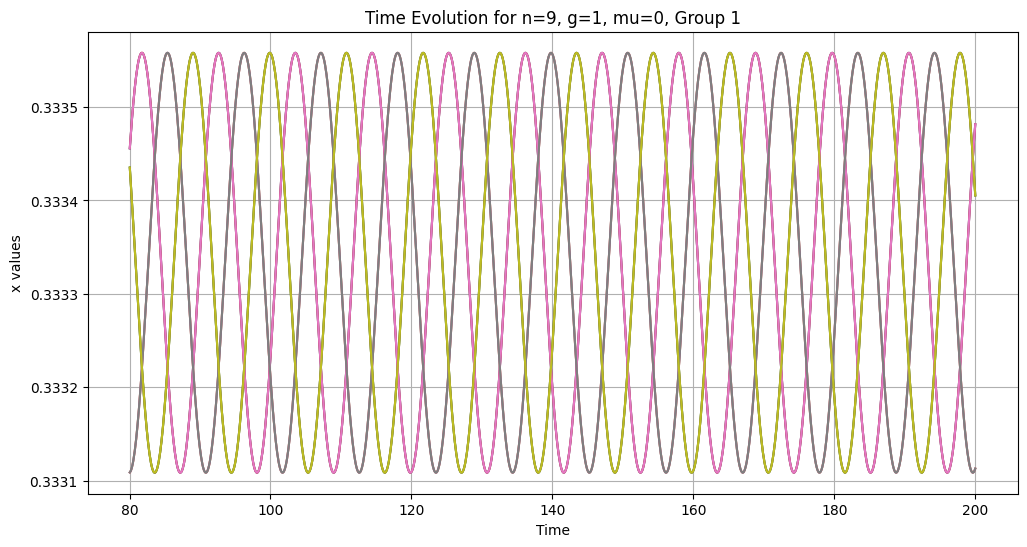

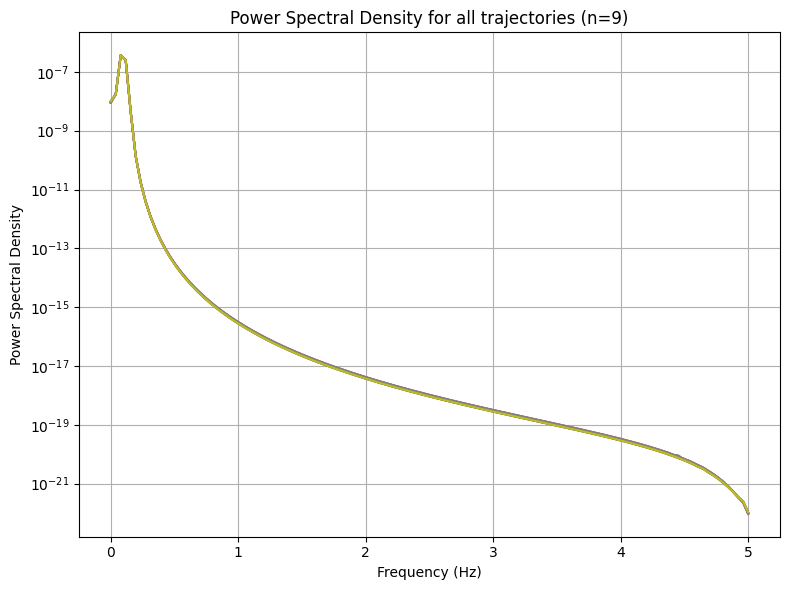

Analyzing Case B: n = 20


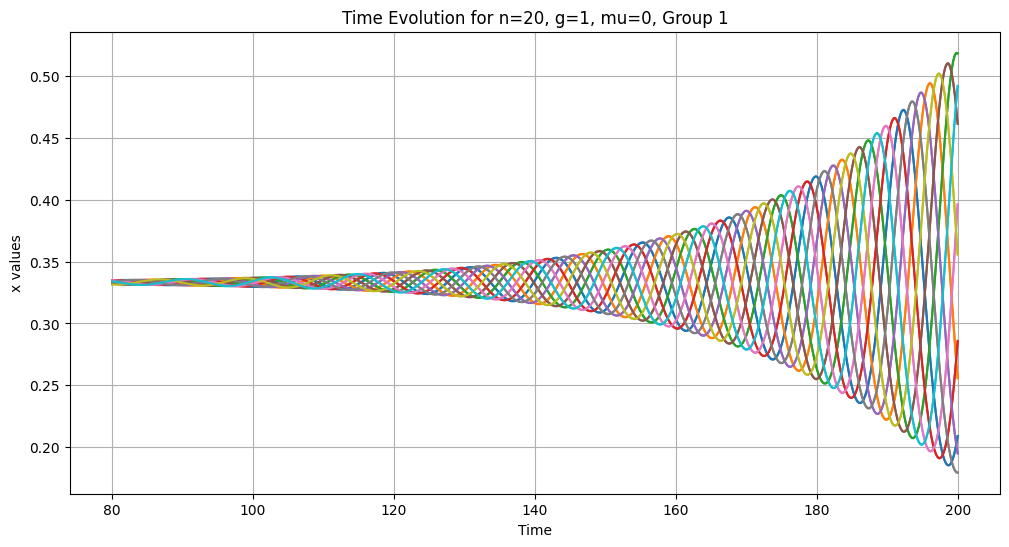

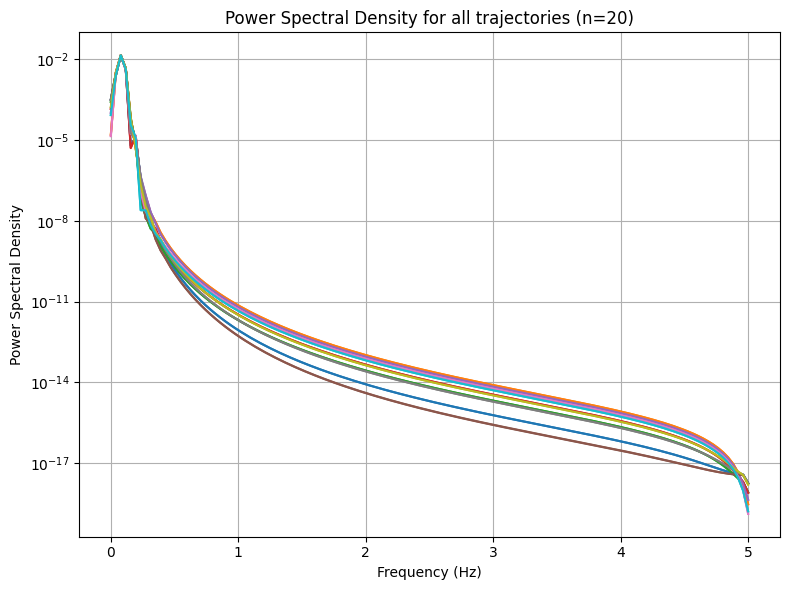

Analyzing Case C: n = 59


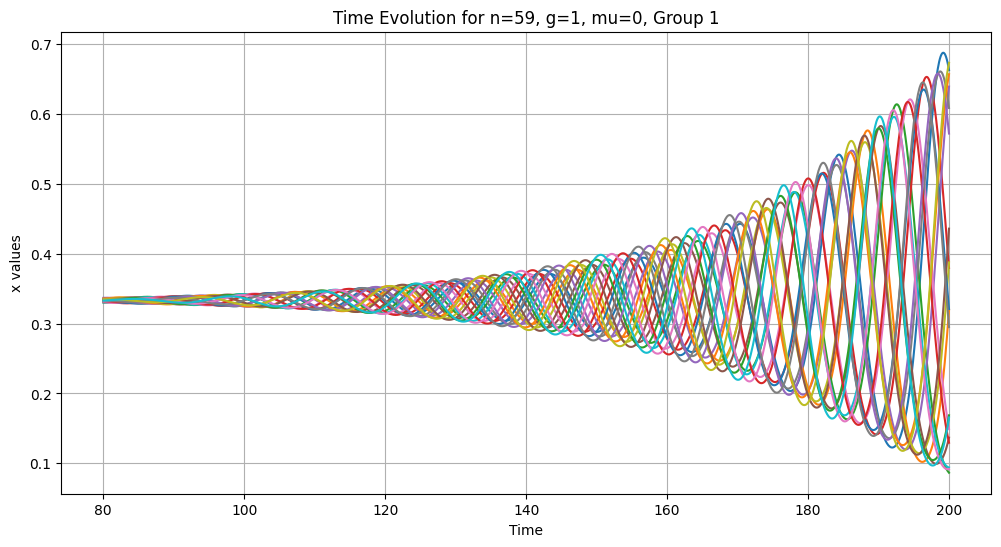

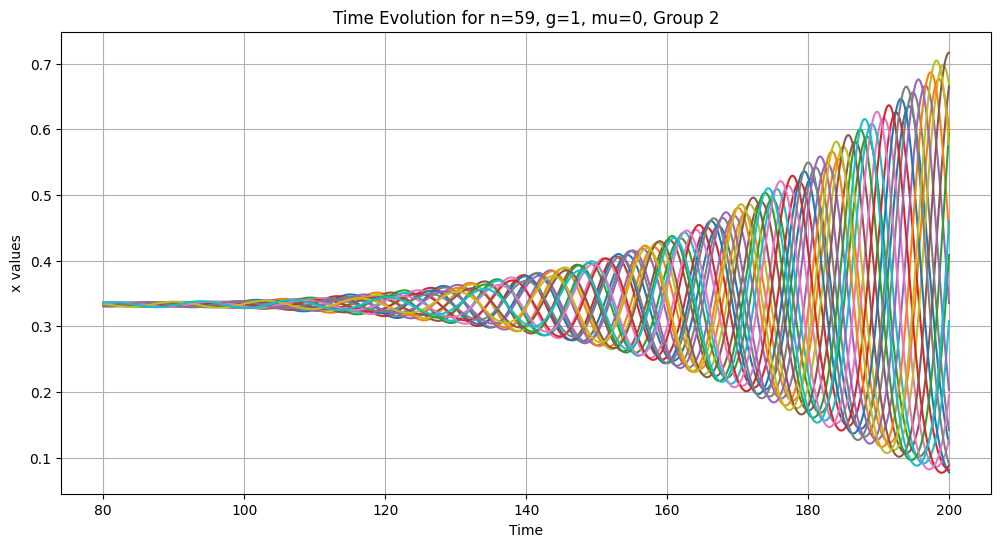

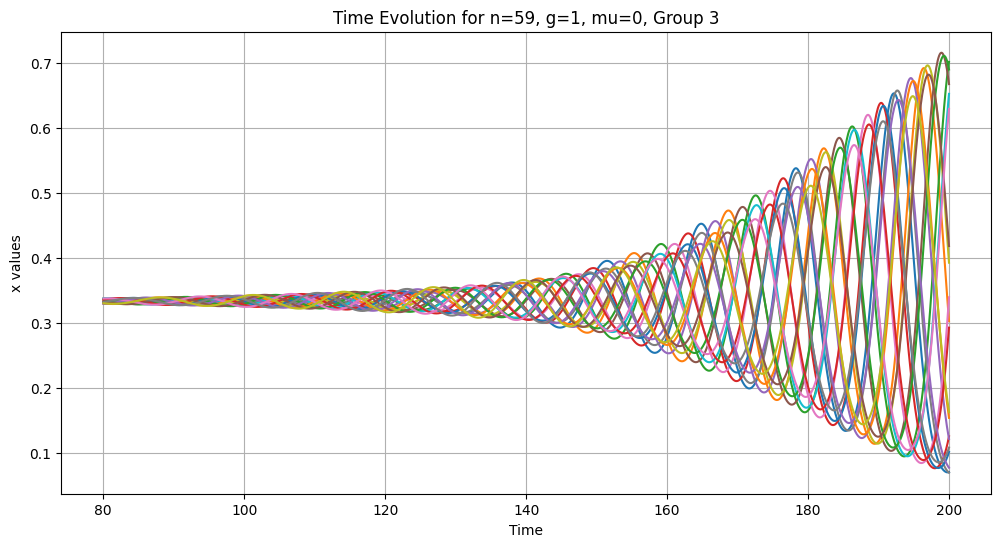

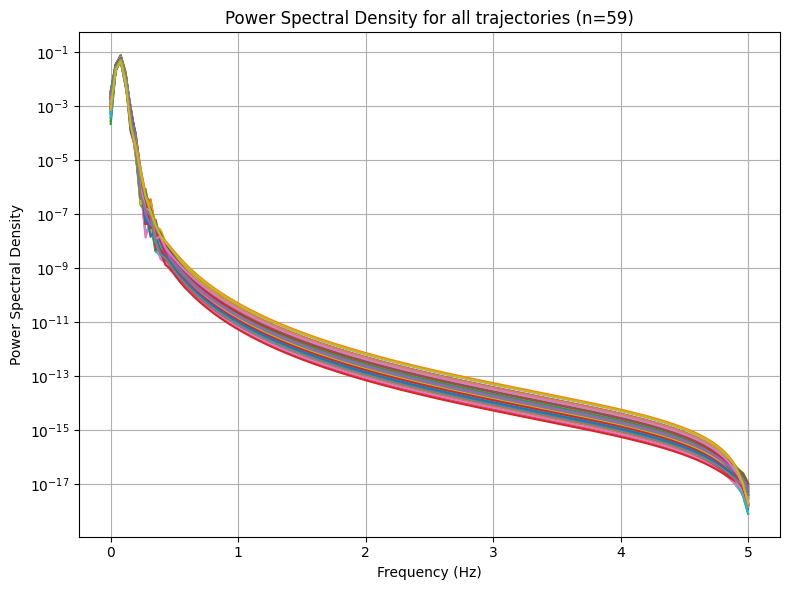

((array([ 80.04002001,  80.14007004,  80.24012006, ..., 199.79989995,
         199.89994997, 200.        ]),
  array([[0.33345576, 0.33346644, 0.33347667, ..., 0.33346113, 0.33347159,
          0.33348159],
         [0.33310889, 0.33310996, 0.33311176, ..., 0.33310941, 0.33311084,
          0.33311301],
         [0.33343528, 0.33342354, 0.3334115 , ..., 0.33342946, 0.33341757,
          0.3334054 ],
         ...,
         [0.33345587, 0.33346654, 0.33347677, ..., 0.33346113, 0.33347159,
          0.33348159],
         [0.33310904, 0.33311011, 0.33311191, ..., 0.33310941, 0.33311084,
          0.33311301],
         [0.33343522, 0.33342349, 0.33341145, ..., 0.33342946, 0.33341757,
          0.3334054 ]])),
 (array([ 80.04002001,  80.14007004,  80.24012006, ..., 199.79989995,
         199.89994997, 200.        ]),
  array([[0.33467593, 0.33473932, 0.33479982, ..., 0.20187375, 0.2051524 ,
          0.20874044],
         [0.33188589, 0.33192495, 0.33196808, ..., 0.27000716, 0.26286377,
    

In [37]:
part1q2()

In [10]:
def part1q2():
    """Part 1, question 2:
    Add input/output if/as needed.
    """

    import numpy as np
    import matplotlib.pyplot as plt

    def analyze_case(n, g, mu, Nt, tf):
        """
        Analyzes a single case and produces plots and statistics.
        """
        X0 = -1
        # Simulate the system
        t, X = simulate1(n=n, X0=X0, tf=tf, g=g, mu=mu, flag_display=False)

        # Discard the transient (e.g., first 10% of time)
        transient_cutoff = int(0.1 * len(t))
        t = t[transient_cutoff:]
        X = X[:, transient_cutoff:]

        # Split the figures for better visualization
        num_figures = (n + 19) // 20  # Divide trajectories into groups of 20
        for fig_idx in range(num_figures):
            plt.figure(figsize=(12, 6))
            start_idx = fig_idx * 20
            end_idx = min(start_idx + 20, n)
            for i in range(start_idx, end_idx):
                plt.plot(t, X[i], label=f"x_{i}")
            plt.xlabel("Time")
            plt.ylabel("x values")
            plt.title(f"Time Evolution for n={n}, g={g}, mu={mu}, Group {fig_idx + 1}")
            plt.grid(True)
            # plt.legend()
            plt.show()

        # Method 1: Autocorrelation
        plt.figure(figsize=(12, 6))
        for i in range(n):
            autocorr = np.correlate(
                X[i] - np.mean(X[i]), X[i] - np.mean(X[i]), mode="full"
            )
            autocorr /= autocorr[len(X[i]) - 1]  # Normalize
            lag = np.arange(-len(X[i]) + 1, len(X[i]))
            plt.plot(lag, autocorr, label=f"x_{i}")

        plt.xlabel("Lag")
        plt.ylabel("Autocorrelation")
        plt.title(f"Autocorrelation for n={n}, g={g}, mu={mu}")
        plt.grid(True)
        # plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize='small')
        plt.tight_layout()
        plt.show()

        # Method 2: Phase Space Analysis
        plt.figure(figsize=(8, 8))
        for i in range(min(n, 10)):  # Plot phase space for up to 10 trajectories
            plt.plot(X[i, :-1], X[i, 1:], label=f"x_{i}")
        plt.xlabel("x(t)")
        plt.ylabel("x(t+1)")
        plt.title(f"Phase Space Plot for n={n}, g={g}, mu={mu}")
        plt.grid(True)
        # plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize='small')
        plt.tight_layout()
        plt.show()

        # Compute statistics
        mean_values = np.mean(X, axis=1)
        std_values = np.std(X, axis=1)

        print(f"Mean values for n={n}: {mean_values}")
        print(f"Standard deviation for n={n}: {std_values}")

        return t, X, mean_values, std_values

    g = 1  # gamma
    mu = 0  # mu

    # Case A: n = 9
    print("Analyzing Case A: n = 9")
    t_A, X_A, mean_A, std_A = analyze_case(n=9, g=g, mu=mu, Nt=1000, tf=500)

    # Case B: n = 20
    print("Analyzing Case B: n = 20")
    t_B, X_B, mean_B, std_B = analyze_case(n=20, g=g, mu=mu, Nt=2000, tf=800)

    # Case C: n = 59
    print("Analyzing Case C: n = 59")
    t_C, X_C, mean_C, std_C = analyze_case(n=59, g=g, mu=mu, Nt=3000, tf=1000)

    # Return results for further analysis
    return (
        (t_A, X_A, mean_A, std_A),
        (t_B, X_B, mean_B, std_B),
        (t_C, X_C, mean_C, std_C),
    )

Analyzing Case A: n = 9


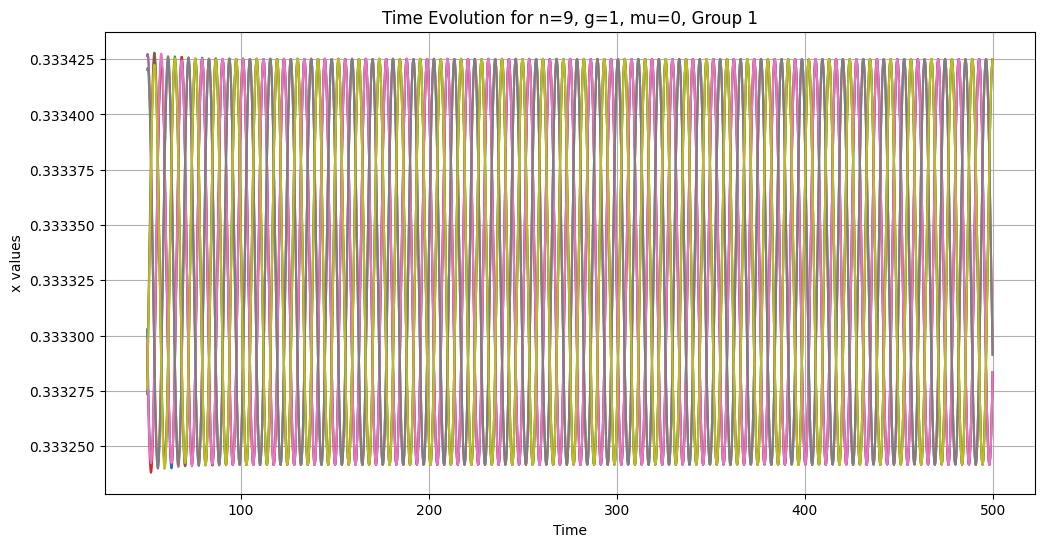

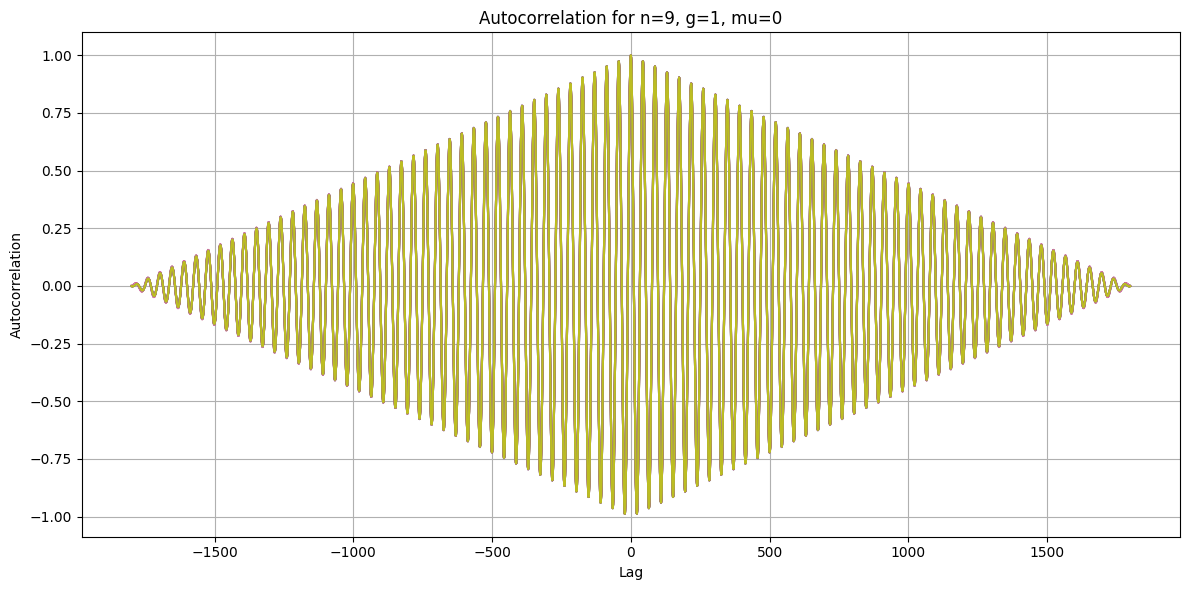

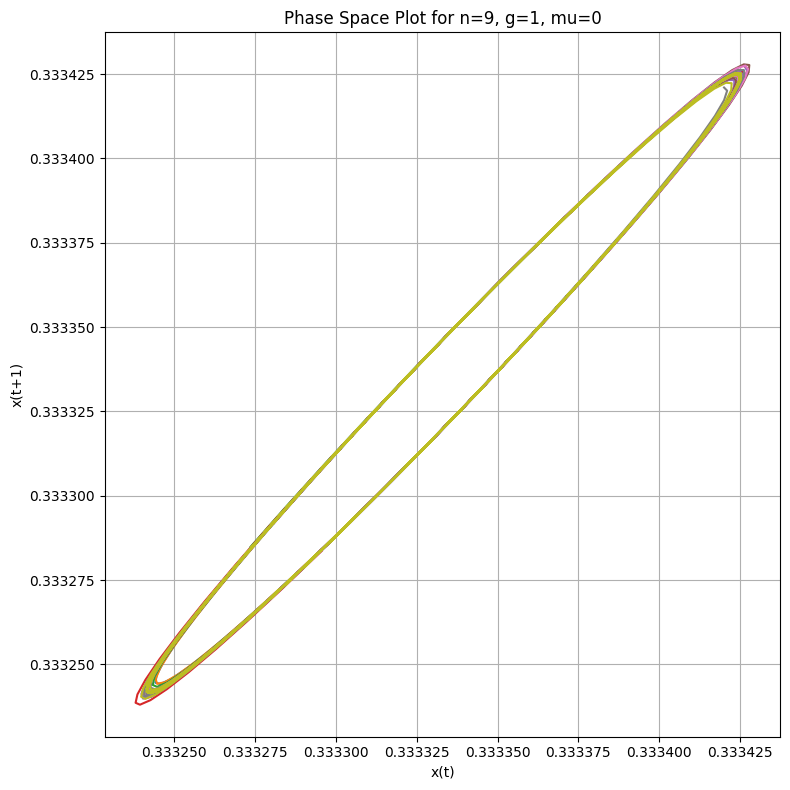

Mean values for n=9: [0.33333269 0.33333375 0.33333362 0.33333265 0.33333368 0.33333363
 0.33333272 0.33333369 0.33333356]
Standard deviation for n=9: [6.49683374e-05 6.48733012e-05 6.48388647e-05 6.50126957e-05
 6.48888584e-05 6.48658641e-05 6.49998650e-05 6.48672113e-05
 6.48371179e-05]
Analyzing Case B: n = 20


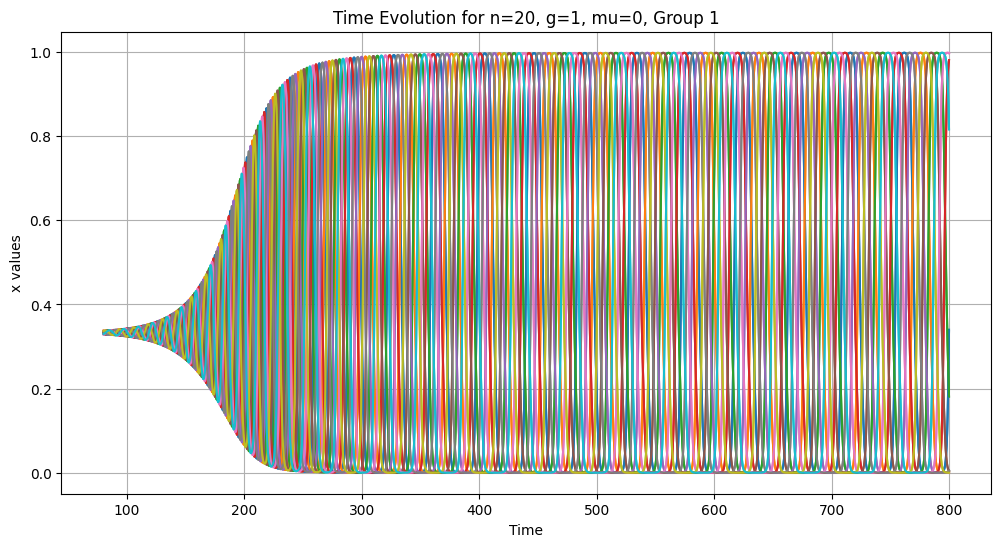

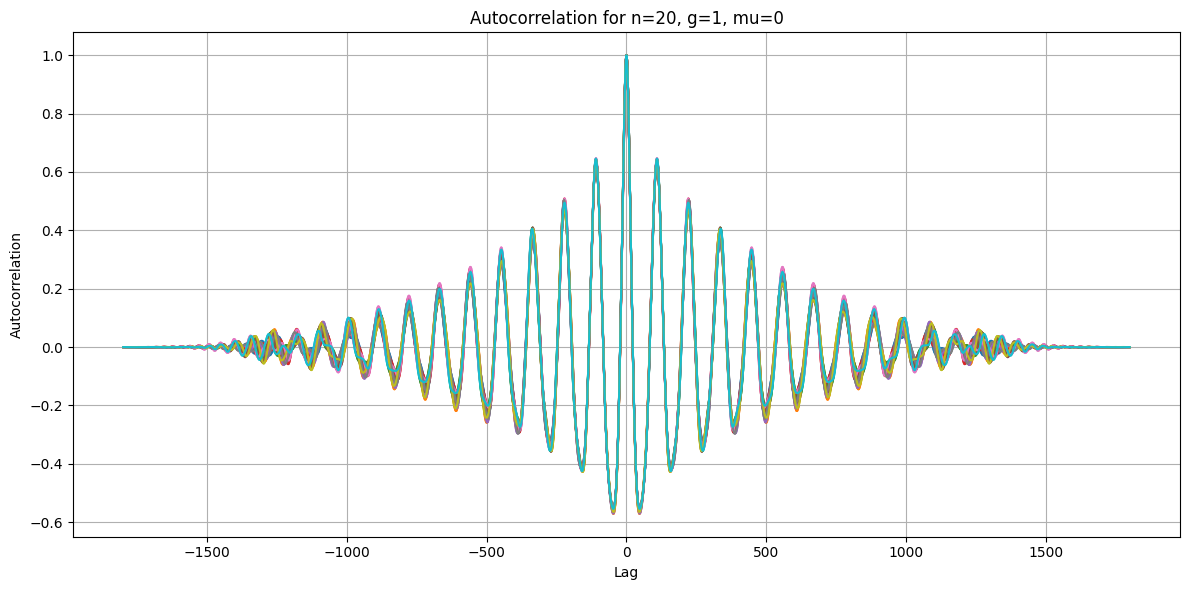

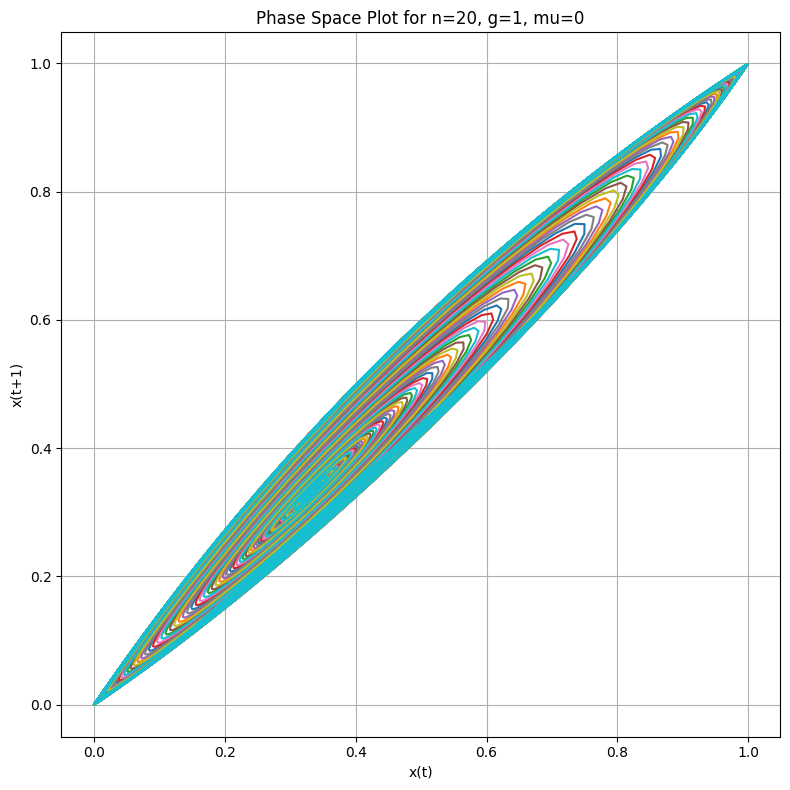

Mean values for n=20: [0.3287302  0.33446072 0.340555   0.3316983  0.33232498 0.33873582
 0.335937   0.33020003 0.33660641 0.33985578 0.32872856 0.33446712
 0.34055487 0.33169143 0.33232546 0.33873224 0.33594062 0.33019524
 0.3365988  0.33986247]
Standard deviation for n=20: [0.36530668 0.36729708 0.36900812 0.36600506 0.36678734 0.36828962
 0.36834202 0.36625666 0.36780052 0.37009509 0.36531388 0.36730082
 0.36901068 0.36600309 0.36678699 0.3682856  0.36834275 0.3662528
 0.36779476 0.37009193]
Analyzing Case C: n = 59


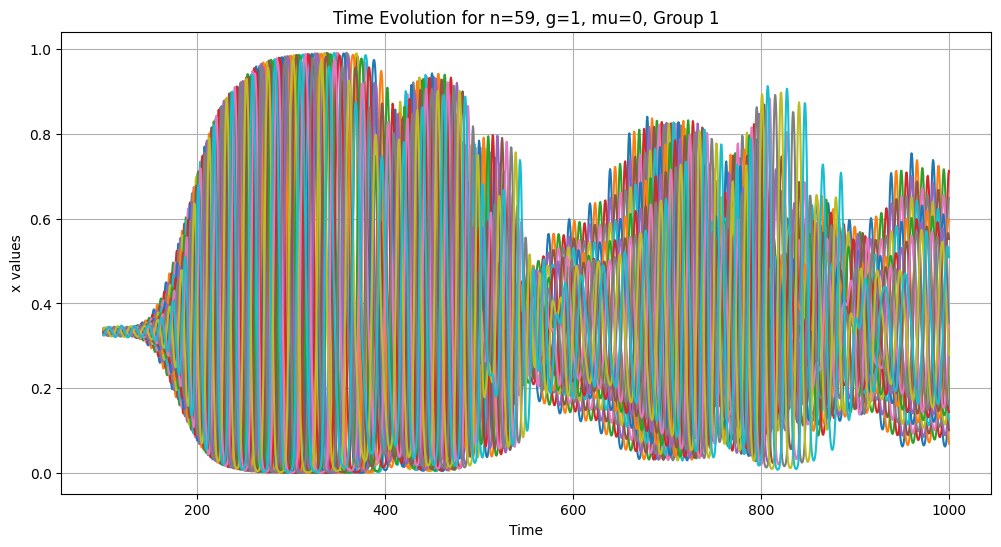

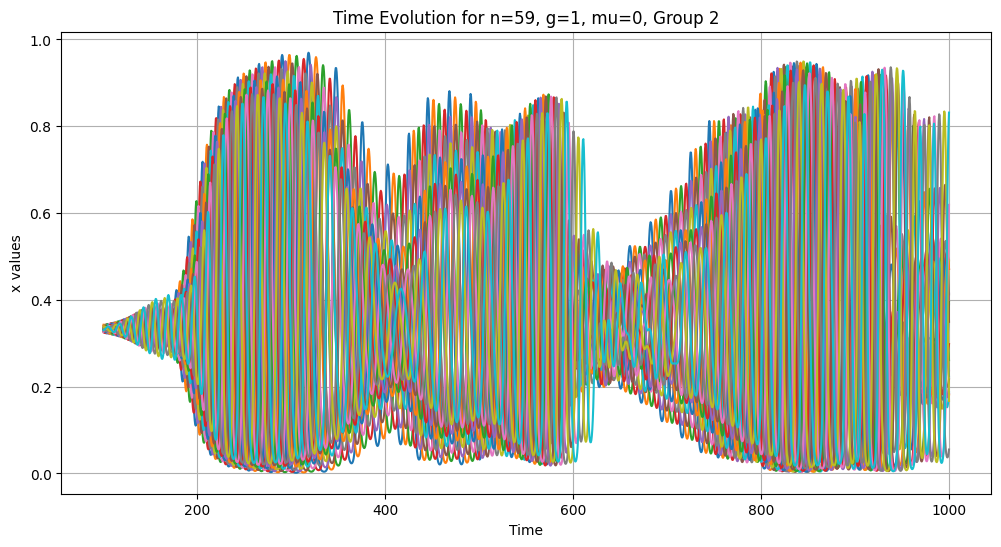

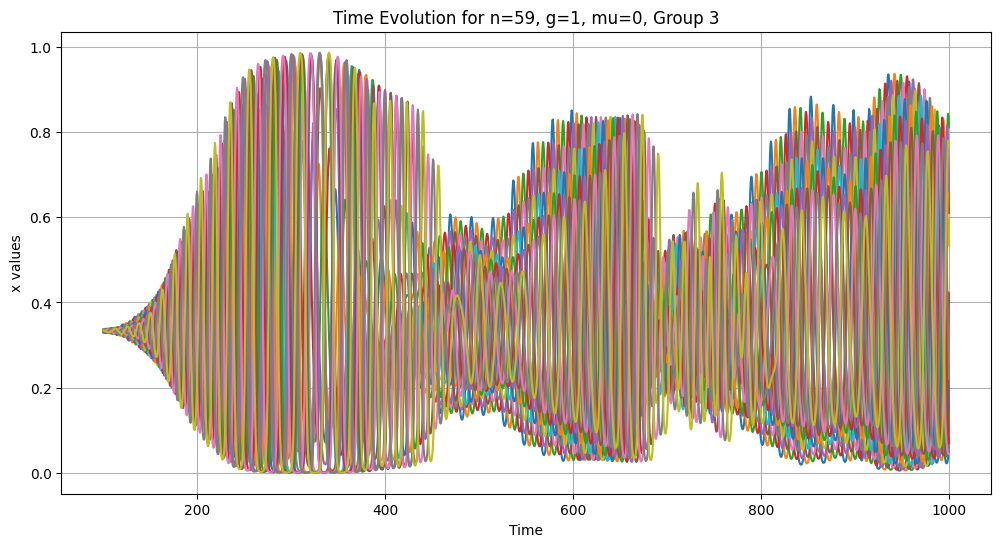

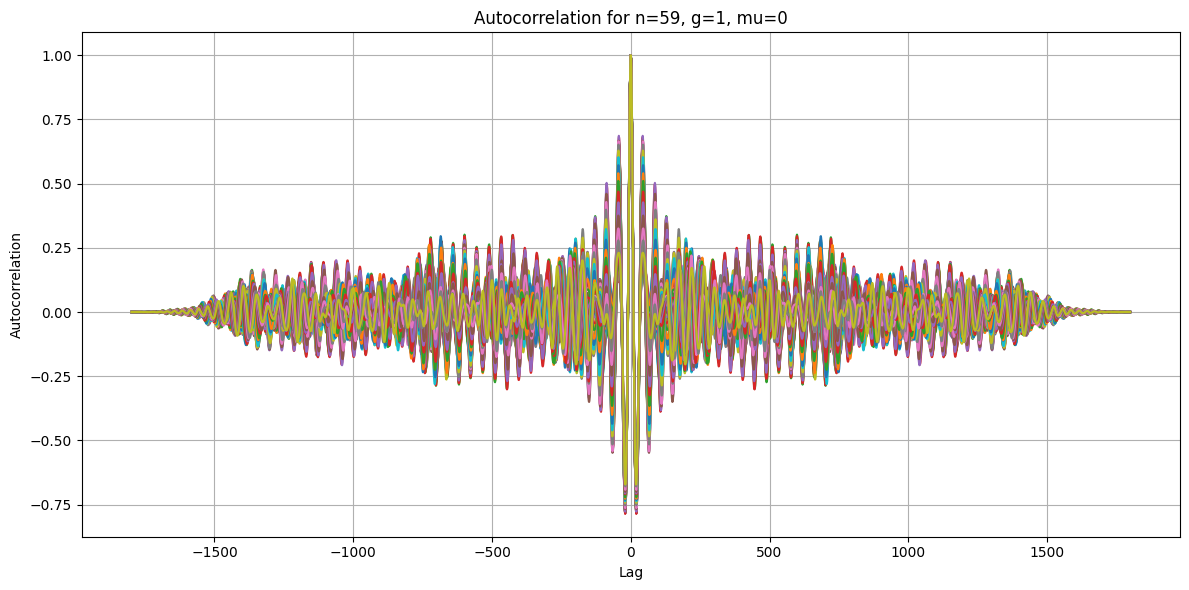

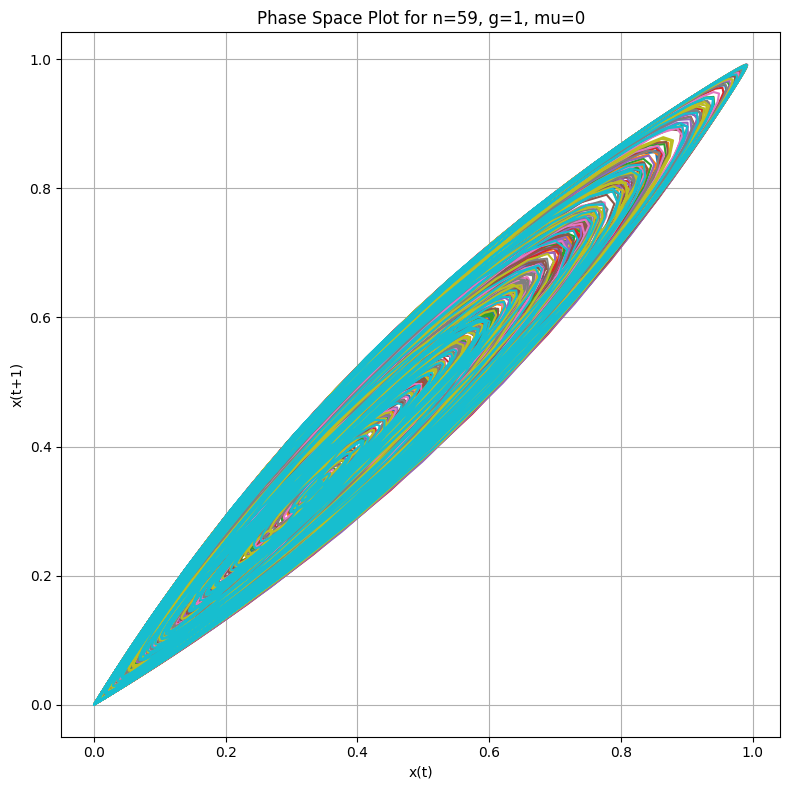

Mean values for n=59: [0.33214039 0.33350792 0.33459009 0.33340877 0.33225097 0.33352321
 0.33442333 0.33340186 0.33235596 0.33342733 0.33426888 0.33349917
 0.33245106 0.33329358 0.33414633 0.33361274 0.33253781 0.33318293
 0.33403752 0.33368099 0.3326523  0.33309328 0.33392364 0.33371503
 0.33280345 0.33302607 0.33372277 0.33384011 0.33293631 0.33291078
 0.33382471 0.33372582 0.33301167 0.3329478  0.3334235  0.33422234
 0.33285629 0.33298143 0.33467654 0.33341583 0.33256433 0.33437026
 0.33423063 0.33223892 0.33367826 0.33446576 0.33270053 0.33322122
 0.33375131 0.3330993  0.33384494 0.33338872 0.3327635  0.33413508
 0.33431597 0.33222976 0.33325885 0.3346503  0.33368707]
Standard deviation for n=59: [0.23637326 0.23666506 0.23686482 0.23666712 0.2367959  0.23837897
 0.24074765 0.24176941 0.24224134 0.24268325 0.24233894 0.24130639
 0.23994088 0.23901782 0.23861527 0.23854232 0.2382778  0.23846172
 0.23888622 0.23951571 0.23957832 0.23970165 0.2396773  0.23980473
 0.23954909 0.2392829

((array([ 50.02501251,  50.27513757,  50.52526263, ..., 499.49974987,
         499.74987494, 500.        ]),
  array([[0.33330285, 0.33329081, 0.33327973, ..., 0.33326368, 0.333273  ,
          0.33328357],
         [0.33342631, 0.33342734, 0.33342645, ..., 0.33331645, 0.33330365,
          0.33329147],
         [0.33327354, 0.33328476, 0.33329693, ..., 0.33341987, 0.33342335,
          0.33342496],
         ...,
         [0.33329794, 0.33328628, 0.33327559, ..., 0.33326368, 0.333273  ,
          0.33328357],
         [0.33342006, 0.33342101, 0.33342007, ..., 0.33331645, 0.33330365,
          0.33329147],
         [0.33327628, 0.33328709, 0.33329885, ..., 0.33341987, 0.33342335,
          0.33342496]]),
  array([0.33333269, 0.33333375, 0.33333362, 0.33333265, 0.33333368,
         0.33333363, 0.33333272, 0.33333369, 0.33333356]),
  array([6.49683374e-05, 6.48733012e-05, 6.48388647e-05, 6.50126957e-05,
         6.48888584e-05, 6.48658641e-05, 6.49998650e-05, 6.48672113e-05,
         6.48

In [11]:
part1q2()